In [5]:
import pandas as pd
from pathlib import Path

CLEAN_DIR = Path("../data/cleaned")

customers = pd.read_csv(CLEAN_DIR / "customers.csv")
products = pd.read_csv(CLEAN_DIR / "products.csv")
orders = pd.read_csv(CLEAN_DIR / "orders.csv")
order_items = pd.read_csv(CLEAN_DIR / "order_items.csv")
payments = pd.read_csv(CLEAN_DIR / "payments.csv")

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Payments:", payments.shape)

Customers: (10000, 8)
Products: (1000, 7)
Orders: (50000, 8)
Order Items: (93308, 7)
Payments: (50000, 6)


In [6]:
print("Total Orders:", orders["order_id"].nunique())
print("Total Customers:", orders["customer_id"].nunique())
print("Order Status:")
print(orders["status"].value_counts())

Total Orders: 50000
Total Customers: 9932
Order Status:
status
Completed    33394
Cancelled     8360
Pending       8246
Name: count, dtype: int64


Matplotlib is building the font cache; this may take a moment.


EXECUTIVE OVERVIEW
Total Orders          : 50,000
Completed Orders      : 33,336
Total Customers       : 10,000
Customers with Orders : 9,641
Revenue               : ₹3,198,112,811.47
Average Order Value   : ₹95,935.71

ORDER STATUS
status
Completed    33394
Cancelled     8360
Pending       8246
Name: count, dtype: int64

MONTHLY REVENUE
  month      revenue
2024-01 9.877667e+07
2024-02 8.922781e+07
2024-03 1.014357e+08
2024-04 9.586772e+07
2024-05 9.766921e+07
2024-06 9.431362e+07
2024-07 9.631994e+07
2024-08 9.602492e+07
2024-09 1.014308e+08
2024-10 9.677227e+07
2024-11 9.515881e+07
2024-12 1.008511e+08
2025-01 9.640666e+07
2025-02 9.573904e+07
2025-03 9.555847e+07
2025-04 9.461573e+07
2025-05 9.539450e+07
2025-06 1.047105e+08
2025-07 9.463029e+07
2025-08 9.931386e+07
2025-09 9.360443e+07
2025-10 9.809042e+07
2025-11 9.755701e+07
2025-12 1.031602e+08
2026-01 9.468073e+07
2026-02 8.304098e+07
2026-03 1.016324e+08
2026-04 9.354309e+07
2026-05 9.946675e+07
2026-06 1.003719e+08
2026-07 9

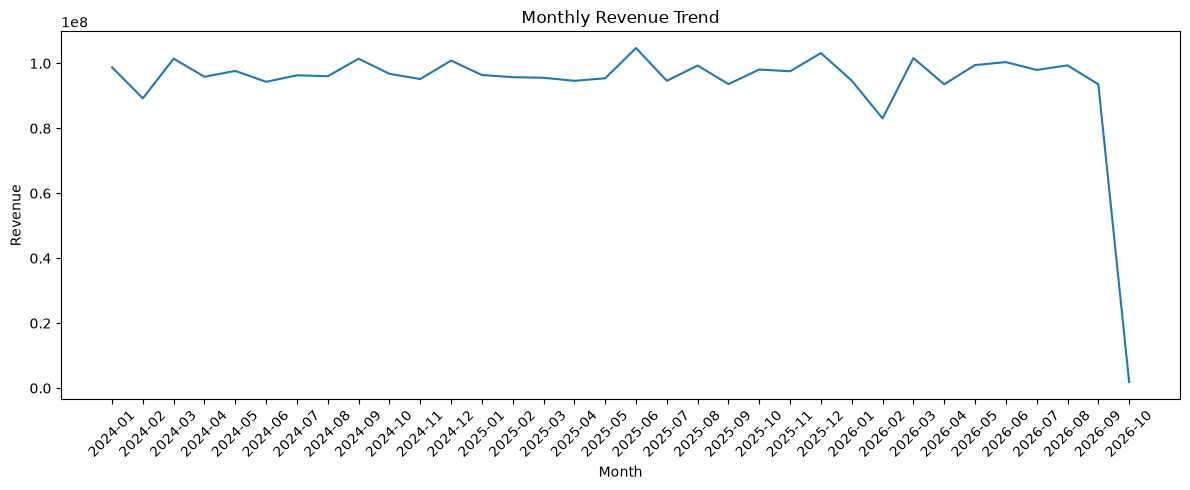

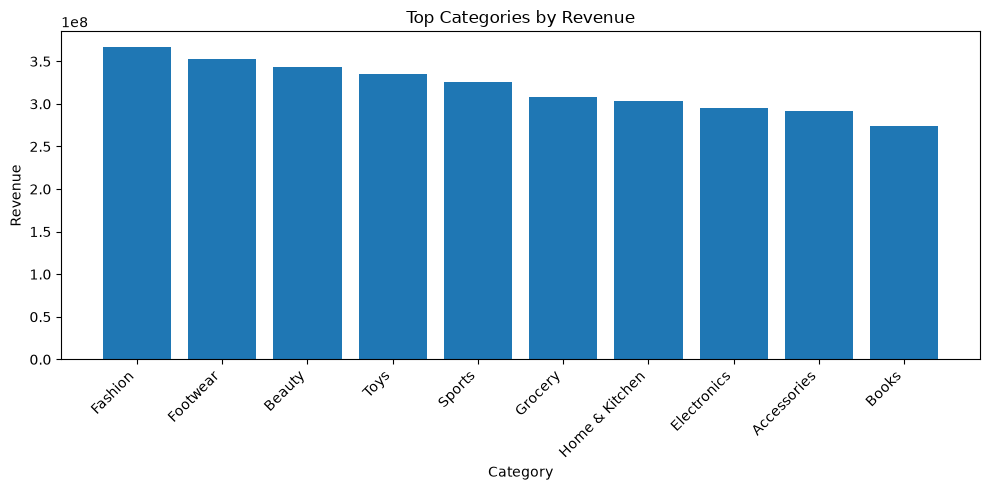


EDA COMPLETED SUCCESSFULLY


In [7]:
# ============================================================
# E-COMMERCE INTELLIGENCE PLATFORM - EDA
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Load data
# -----------------------------
CLEAN = "../data/cleaned/"
RAW = "../data/raw/"

customers = pd.read_csv(CLEAN + "customers.csv")
products = pd.read_csv(CLEAN + "products.csv")
orders = pd.read_csv(CLEAN + "orders.csv")
order_items = pd.read_csv(CLEAN + "order_items.csv")
payments = pd.read_csv(CLEAN + "payments.csv")

categories = pd.read_csv(RAW + "categories.csv")
returns = pd.read_csv(RAW + "returns.csv")
campaigns = pd.read_csv(RAW + "marketing_campaigns.csv")

orders["order_date"] = pd.to_datetime(orders["order_date"])
returns["return_date"] = pd.to_datetime(returns["return_date"])

# -----------------------------
# 1. Revenue Calculation
# -----------------------------
order_items["revenue"] = (
    order_items["quantity"]
    * order_items["unit_price"]
    * (1 - order_items["discount_pct"] / 100)
)

# -----------------------------
# 2. Join Orders + Order Items
# -----------------------------
sales = order_items.merge(
    orders[
        [
            "order_id",
            "customer_id",
            "campaign_id",
            "order_date",
            "status",
            "sales_channel",
            "ship_region"
        ]
    ],
    on="order_id",
    how="left"
)

completed = sales[sales["status"] == "Completed"].copy()

# ============================================================
# EXECUTIVE KPIs
# ============================================================

total_orders = orders["order_id"].nunique()
completed_orders = completed["order_id"].nunique()
total_customers = customers["customer_id"].nunique()
active_customers = completed["customer_id"].nunique()

revenue = completed["revenue"].sum()
aov = revenue / completed_orders

print("=" * 60)
print("EXECUTIVE OVERVIEW")
print("=" * 60)
print(f"Total Orders          : {total_orders:,}")
print(f"Completed Orders      : {completed_orders:,}")
print(f"Total Customers       : {total_customers:,}")
print(f"Customers with Orders : {active_customers:,}")
print(f"Revenue               : ₹{revenue:,.2f}")
print(f"Average Order Value   : ₹{aov:,.2f}")

# ============================================================
# ORDER STATUS
# ============================================================

print("\n" + "=" * 60)
print("ORDER STATUS")
print("=" * 60)

status = orders["status"].value_counts()
print(status)

# ============================================================
# MONTHLY REVENUE
# ============================================================

monthly = (
    completed.assign(
        month=completed["order_date"].dt.to_period("M").astype(str)
    )
    .groupby("month")["revenue"]
    .sum()
    .reset_index()
)

print("\n" + "=" * 60)
print("MONTHLY REVENUE")
print("=" * 60)
print(monthly.to_string(index=False))

# ============================================================
# CATEGORY REVENUE
# ============================================================

product_category = products.merge(
    categories,
    on="category_id",
    how="left"
)

category_sales = completed.merge(
    product_category[["product_id", "category_name"]],
    on="product_id",
    how="left"
)

category_revenue = (
    category_sales
    .groupby("category_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\n" + "=" * 60)
print("TOP CATEGORIES")
print("=" * 60)
print(category_revenue.head(10))

# ============================================================
# TOP PRODUCTS
# ============================================================

top_products = (
    completed
    .groupby("product_id")
    .agg(
        revenue=("revenue", "sum"),
        quantity_sold=("quantity", "sum")
    )
    .sort_values("revenue", ascending=False)
    .reset_index()
    .merge(
        products[["product_id", "product_name", "brand"]],
        on="product_id",
        how="left"
    )
)

print("\n" + "=" * 60)
print("TOP 10 PRODUCTS")
print("=" * 60)

print(
    top_products[
        ["product_id", "product_name", "brand",
         "quantity_sold", "revenue"]
    ].head(10).to_string(index=False)
)

# ============================================================
# TOP CUSTOMERS
# ============================================================

top_customers = (
    completed
    .groupby("customer_id")
    .agg(
        revenue=("revenue", "sum"),
        orders=("order_id", "nunique")
    )
    .sort_values("revenue", ascending=False)
    .reset_index()
)

print("\n" + "=" * 60)
print("TOP 10 CUSTOMERS")
print("=" * 60)
print(top_customers.head(10).to_string(index=False))

# ============================================================
# SALES CHANNEL
# ============================================================

channel = (
    completed
    .groupby("sales_channel")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\n" + "=" * 60)
print("SALES CHANNEL")
print("=" * 60)
print(channel)

# ============================================================
# RETURNS
# ============================================================

print("\n" + "=" * 60)
print("RETURNS")
print("=" * 60)

print("Total Returns:", len(returns))
print("Total Refund: ₹", round(returns["refund_amount"].sum(), 2))

print("\nReturn Reasons:")
print(returns["reason"].value_counts())

# ============================================================
# CAMPAIGNS
# ============================================================

campaign_sales = completed[
    completed["campaign_id"].notna()
].copy()

campaign_sales["campaign_id"] = (
    campaign_sales["campaign_id"].astype(int)
)

campaign_performance = (
    campaign_sales
    .groupby("campaign_id")
    .agg(
        revenue=("revenue", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
    .merge(
        campaigns[
            ["campaign_id", "name", "channel",
             "budget", "discount_pct"]
        ],
        on="campaign_id",
        how="left"
    )
    .sort_values("revenue", ascending=False)
)

print("\n" + "=" * 60)
print("TOP 10 CAMPAIGNS")
print("=" * 60)

print(
    campaign_performance.head(10).to_string(index=False)
)

# ============================================================
# CHART 1 - MONTHLY REVENUE
# ============================================================

plt.figure(figsize=(12, 5))
plt.plot(monthly["month"], monthly["revenue"])
plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# ============================================================
# CHART 2 - CATEGORY REVENUE
# ============================================================

plt.figure(figsize=(10, 5))
top_cat = category_revenue.head(10)

plt.bar(top_cat.index, top_cat.values)
plt.xticks(rotation=45, ha="right")
plt.title("Top Categories by Revenue")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("EDA COMPLETED SUCCESSFULLY")
print("=" * 60)